In [599]:
import numpy as np

In [600]:
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.linalg import splu
from scipy.stats import qmc
from scipy.spatial import cKDTree
from scipy.spatial import Voronoi, voronoi_plot_2d

In [601]:
%pip install triangle
import triangle as tr

In [602]:
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
from matplotlib.path import Path
from matplotlib import tri
from matplotlib.animation import FuncAnimation
plt.rcParams["animation.embed_limit"] = 200
from IPython.display import HTML, Video, display

# Геометрия комнаты Пенроуза

Рассмотрим двумерную связную невыпуклую область $\Omega\subset\mathbb{R}^2$, симметричную относительно координатных осей. Её граница $\partial\Omega$ состоит из двух внешних полуэллипсов, двух боковых эллиптических выступов и соединительных прямолинейных участков.

Введём параметры:

- $a$ — горизонтальная полуось внешних эллипсов;
- $b$ — вертикальная полуось внешних эллипсов;
- $c=\sqrt{a^2-b^2}$ — фокусное расстояние внешних эллипсов;
- $h$ — половина высоты центральной полосы и вертикальная полуось боковых выступов;
- $r$ — горизонтальная полуось боковых выступов;
- $s$ — половина толщины прямоугольных соединительных участков.

Потребуем:

$$
a>b>0,\qquad 0<s<h,\qquad 0<r<c.
$$

Габариты области:

$$
-a\le x\le a,\qquad -(b+h)\le y\le b+h.
$$

## Границы

### Верхняя граница

Верхний полуэллипс с центром $(0,h)$:

$$
\boxed{
\frac{x^2}{a^2}+\frac{(y-h)^2}{b^2}=1,
\qquad y\ge h.
}
$$

Параметризация:

$$
\boxed{
\gamma_T(t)=
\begin{pmatrix}
a\cos t\\
h+b\sin t
\end{pmatrix},
\qquad t\in[0,\pi].
}
$$

Фокусы: $(-c,h)$ и $(c,h)$.

### Нижняя граница

Нижний полуэллипс с центром $(0,-h)$:

$$
\boxed{
\frac{x^2}{a^2}+\frac{(y+h)^2}{b^2}=1,
\qquad y\le-h.
}
$$

Параметризация:

$$
\boxed{
\gamma_B(t)=
\begin{pmatrix}
a\cos t\\
-h-b\sin t
\end{pmatrix},
\qquad t\in[\pi,2\pi].
}
$$

Фокусы: $(-c,-h)$ и $(c,-h)$.

### Левый выступ

Правая половина эллипса с центром $(-c,0)$ и полуосями $(r,h)$:

$$
\boxed{
\frac{(x+c)^2}{r^2}+\frac{y^2}{h^2}=1,
\qquad x\ge-c.
}
$$

В явном виде:

$$
x=-c+r\sqrt{1-\frac{y^2}{h^2}},
\qquad y\in[-h,h].
$$

Параметризация:

$$
\boxed{
\gamma_L(t)=
\begin{pmatrix}
-c+r\sin t\\
h\cos t
\end{pmatrix},
\qquad t\in[0,\pi].
}
$$

Концы выступа: $(-c,h)$ и $(-c,-h)$.

### Правый выступ

Левая половина эллипса с центром $(c,0)$ и полуосями $(r,h)$:

$$
\boxed{
\frac{(x-c)^2}{r^2}+\frac{y^2}{h^2}=1,
\qquad x\le c.
}
$$

В явном виде:

$$
x=c-r\sqrt{1-\frac{y^2}{h^2}},
\qquad y\in[-h,h].
$$

Параметризация:

$$
\boxed{
\gamma_R(t)=
\begin{pmatrix}
c-r\sin t\\
h\cos t
\end{pmatrix},
\qquad t\in[0,\pi].
}
$$

Концы выступа: $(c,h)$ и $(c,-h)$.

### 5. Прямолинейные соединения

Между внешними эллипсами и боковыми выступами расположены четыре ступенчатых участка границы.

Правый верхний:

$$
(a,h)\to(a,s)\to(c,s)\to(c,h).
$$

Правый нижний:

$$
(c,-h)\to(c,-s)\to(a,-s)\to(a,-h).
$$

Левый верхний:

$$
(-c,h)\to(-c,s)\to(-a,s)\to(-a,h).
$$

Левый нижний:

$$
(-a,-h)\to(-a,-s)\to(-c,-s)\to(-c,-h).
$$

Каждый отрезок между точками $P$ и $Q$ параметризуется линейно:

$$
\boxed{
\gamma_{PQ}(t)=(1-t)P+tQ,\qquad t\in[0,1].
}
$$

In [603]:
a = 9.0
b = 6.0
h = 2.0
r = 1.5
s = 0.75

c = np.sqrt(a**2 - b**2)

assert a > b > 0, "Требуется a > b > 0"
assert 0 < s < h, "Требуется 0 < s < h"
assert 0 < r < c, "Требуется 0 < r < c"
assert c + r < a, "Боковые выступы должны помещаться в пределах области"

In [604]:
def upper_boundary(t):
    return a * np.cos(t), h + b * np.sin(t)

def lower_boundary(t):
    return a * np.cos(t), -h + b * np.sin(t)

def left_boundary(t):
    return -c + r * np.sin(t), h * np.cos(t)

def right_boundary(t):
    return c - r * np.sin(t), h * np.cos(t)

def segment(t, P, Q):
    x = (1 - t) * P[0] + t * Q[0]
    y = (1 - t) * P[1] + t * Q[1]
    return x, y

# Построение сетки

In [605]:
grid_step = 0.08

In [606]:
def add_curve(fn, t0, t1, ds):
    t = np.linspace(t0, t1, 1000)
    x, y = fn(t)

    lengths = np.r_[0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    n = max(2, int(np.ceil(lengths[-1] / ds)))

    t = np.interp(np.linspace(0, lengths[-1], n, endpoint=False), lengths, t)
    return np.column_stack(fn(t))


def add_segment(P, Q, ds):
    n = max(1, int(np.ceil(np.linalg.norm(np.subtract(Q, P)) / ds)))
    t = np.linspace(0, 1, n, endpoint=False)
    return np.column_stack(segment(t, P, Q))


def make_boundary(ds=0.1):
    parts = [
        add_curve(upper_boundary, 0, np.pi, ds),

        add_segment((-a, h), (-a, s), ds),
        add_segment((-a, s), (-c, s), ds),
        add_segment((-c, s), (-c, h), ds),

        add_curve(left_boundary, 0, np.pi, ds),

        add_segment((-c, -h), (-c, -s), ds),
        add_segment((-c, -s), (-a, -s), ds),
        add_segment((-a, -s), (-a, -h), ds),

        add_curve(lower_boundary, np.pi, 2 * np.pi, ds),

        add_segment((a, -h), (a, -s), ds),
        add_segment((a, -s), (c, -s), ds),
        add_segment((c, -s), (c, -h), ds),

        add_curve(right_boundary, np.pi, 0, ds),

        add_segment((c, h), (c, s), ds),
        add_segment((c, s), (a, s), ds),
        add_segment((a, s), (a, h), ds),
    ]

    return np.vstack(parts).T


xs_b, ys_b = make_boundary(ds=grid_step)
print(f"Количество граничных узлов: {len(xs_b)}")

Количество граничных узлов: 980


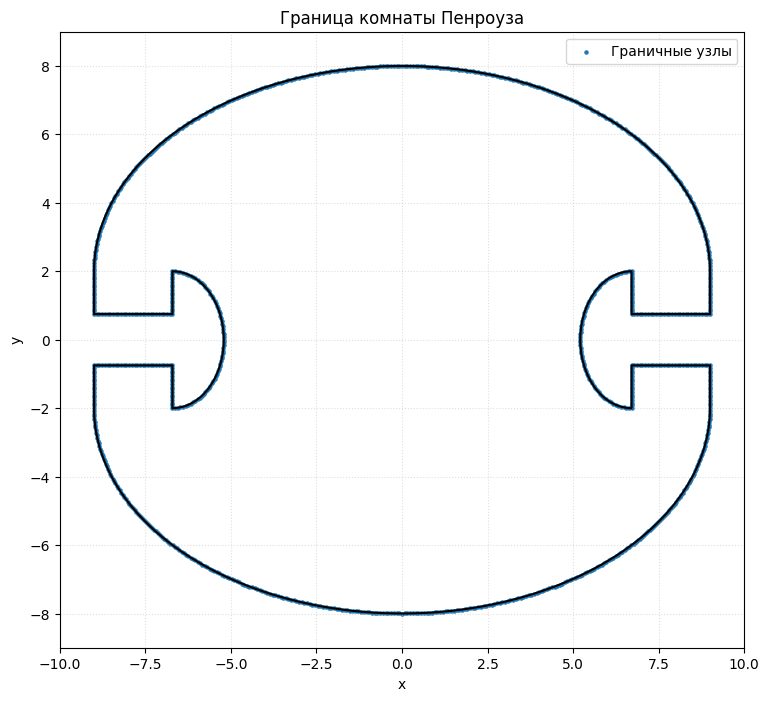

In [607]:
fig, ax = plt.subplots(figsize=(10, 8), dpi=100)

ax.plot(
    np.r_[xs_b, xs_b[0]],
    np.r_[ys_b, ys_b[0]],
    color="black", lw=1.5
)

ax.scatter(xs_b, ys_b, s=5, color="tab:blue", label="Граничные узлы")

ax.set(
    xlabel="x", ylabel="y",
    title="Граница комнаты Пенроуза",
    xlim=(-a - 1, a + 1),
    ylim=(-b - h - 1, b + h + 1)
)

ax.set_aspect("equal")
ax.grid(ls=":", alpha=0.4)
ax.legend()

plt.show()

In [608]:
def make_inner_nodes(xs_b, ys_b, ds=0.25, seed=42):
    bounds = np.array([[-a, a], [-b-h, b+h]])
    area = np.prod(bounds[:, 1] - bounds[:, 0])

    n = int(np.ceil(area / (np.sqrt(3) / 2 * ds**2)))
    sampler = qmc.Sobol(d=2, scramble=True, seed=seed)
    points = qmc.scale(
        sampler.random_base2(int(np.ceil(np.log2(n)))),
        bounds[:, 0], bounds[:, 1]
    )

    boundary = np.column_stack((xs_b, ys_b))
    polygon = Path(np.vstack((boundary, boundary[0])))

    points = points[polygon.contains_points(points)]

    distances, _ = cKDTree(boundary).query(points)
    points = points[distances > ds / 2]

    return points[:, 0], points[:, 1]


xs_i, ys_i = make_inner_nodes(xs_b, ys_b, ds=grid_step)
print(f"Внутренних узлов: {len(xs_i)}")
print(f"Граничных узлов: {len(xs_b)}")

Внутренних узлов: 50736
Граничных узлов: 980


In [609]:
def make_mesh(xs, ys, n_inner):
    points = np.column_stack((xs, ys))
    n = len(points)

    boundary_ids = np.arange(n_inner, n)
    segments = np.column_stack((
        boundary_ids,
        np.roll(boundary_ids, -1)
    ))

    data = {"vertices": points, "segments": segments}
    result = tr.triangulate(data, "p")

    vertices = result["vertices"]
    elems = result["triangles"]

    mesh = tri.Triangulation(vertices[:, 0], vertices[:, 1], elems)

    return mesh

In [610]:
def smoothing(mesh, n_inner, n_iter=15):
    xs, ys = mesh.x.copy(), mesh.y.copy()

    triangles = mesh.get_masked_triangles()
    edges = np.vstack((
        triangles[:, [0, 1]],
        triangles[:, [1, 2]],
        triangles[:, [2, 0]]
    ))
    edges = np.unique(np.sort(edges, axis=1), axis=0)

    rows = np.r_[edges[:, 0], edges[:, 1]]
    cols = np.r_[edges[:, 1], edges[:, 0]]

    mask = rows < n_inner
    S = sp.csr_matrix(
        (np.ones(mask.sum()), (rows[mask], cols[mask])),
        shape=(n_inner, len(xs))
    )

    S = sp.diags(1.0 / np.asarray(S.sum(axis=1)).ravel()) @ S

    for _ in range(n_iter):
        xs[:n_inner] = S @ xs
        ys[:n_inner] = S @ ys

    return xs, ys

In [611]:
xs = np.r_[xs_i, xs_b]
ys = np.r_[ys_i, ys_b]
n_inner = len(xs_i)

mesh = make_mesh(xs, ys, n_inner)

print("Узлов до:", len(xs))
print("Узлов после:", len(mesh.x))

xs, ys = smoothing(mesh, n_inner)
mesh = make_mesh(xs, ys, n_inner)

print("Узлов до:", len(xs))
print("Узлов после:", len(mesh.x))

Узлов до: 51716
Узлов после: 51716
Узлов до: 51716
Узлов после: 51716


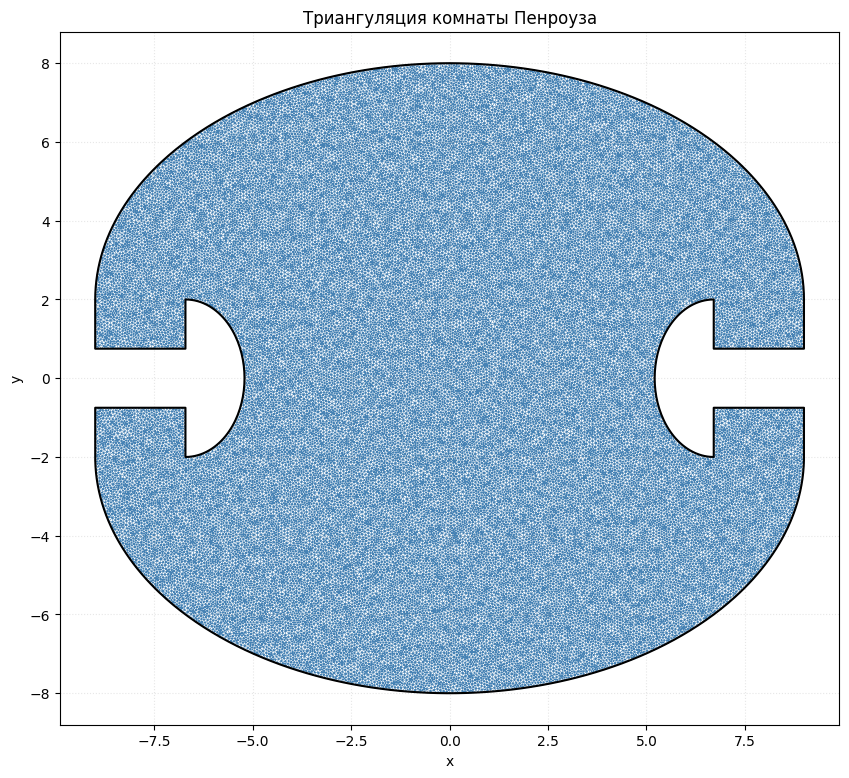

In [612]:
fig, ax = plt.subplots(figsize=(11, 9), dpi=100)

ax.triplot(mesh, color="steelblue", lw=0.45)
ax.plot(np.r_[xs_b, xs_b[0]],
        np.r_[ys_b, ys_b[0]], color="black", lw=1.5)

ax.set(
    xlabel="x", ylabel="y",
    title=f"Триангуляция комнаты Пенроуза"
)

ax.set_aspect("equal")
ax.grid(ls=":", alpha=0.3)
plt.show()

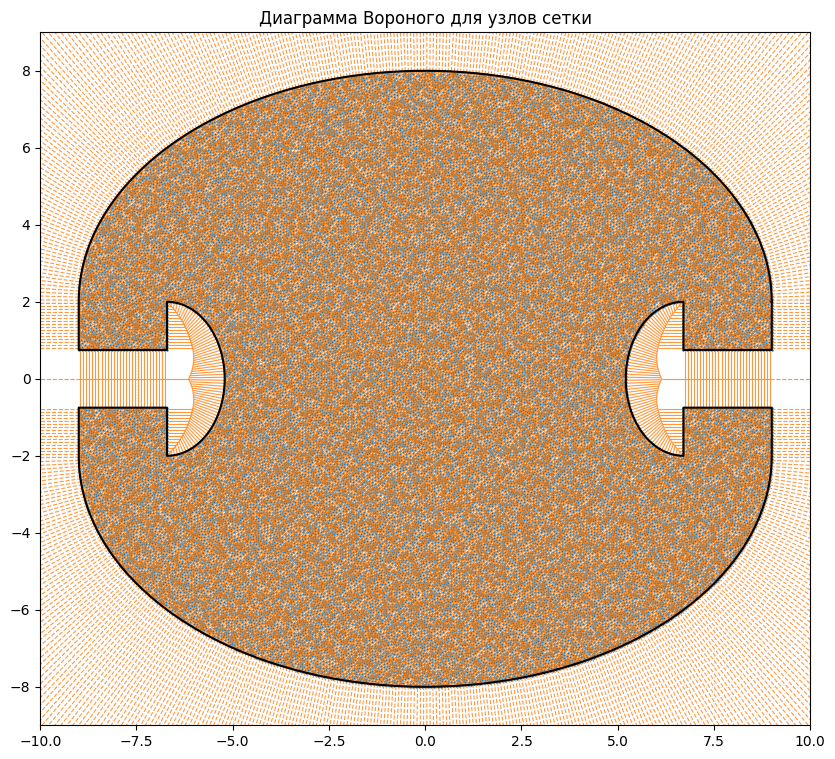

In [613]:
points = np.column_stack((xs, ys))
vor = Voronoi(points)

fig, ax = plt.subplots(figsize=(11, 9), dpi=100)

voronoi_plot_2d(
    vor,
    ax=ax,
    show_vertices=False,
    line_colors="tab:orange",
    line_width=0.8,
    line_alpha=0.8,
    point_size=1.5
)

ax.plot(np.r_[xs_b, xs_b[0]], np.r_[ys_b, ys_b[0]], color="black", lw=1.5)
ax.set_aspect("equal")
ax.set_xlim(-a - 1, a + 1)
ax.set_ylim(-(b + h) - 1, b + h + 1)
ax.grid(ls=":", alpha=0.3)
ax.set_title("Диаграмма Вороного для узлов сетки")
plt.show()

# FEM-геометрия

In [614]:
def element_geometry(mesh):
    elems = mesh.get_masked_triangles()
    x, y = mesh.x, mesh.y

    i, j, k = elems.T

    xc = (x[i] + x[j] + x[k]) / 3
    yc = (y[i] + y[j] + y[k]) / 3

    det = (x[j] - x[i]) * (y[k] - y[i]) \
        - (x[k] - x[i]) * (y[j] - y[i])

    area = np.abs(det) / 2

    if np.any(area <= 1e-12):
        raise ValueError("Обнаружены вырожденные треугольники")

    gx = np.column_stack((
        y[j] - y[k],
        y[k] - y[i],
        y[i] - y[j]
    )) / det[:, None]

    gy = np.column_stack((
        x[k] - x[j],
        x[i] - x[k],
        x[j] - x[i]
    )) / det[:, None]

    grad = np.stack((gx, gy), axis=-1)

    return elems, (xc, yc), area, grad


elems, (xc, yc), area, grad = element_geometry(mesh)

print(f"Количество элементов: {len(elems)}")
print(f"Площадь области: {area.sum():.6f}")
print(f"Минимальная площадь элемента: {area.min():.6e}")
print(f"Максимальная площадь элемента: {area.max():.6e}")

print(f"Максимальная ошибка суммы градиентов: "
      f"{np.abs(grad.sum(axis=1)).max():.3e}")

Количество элементов: 102450
Площадь области: 225.345760
Минимальная площадь элемента: 3.242050e-04
Максимальная площадь элемента: 5.963302e-03
Максимальная ошибка суммы градиентов: 7.105e-15


In [615]:
elems, (xc, yc), area, grad = element_geometry(mesh)

boundary_area = 0.5 * abs(
    np.dot(xs_b, np.roll(ys_b, -1))
    - np.dot(ys_b, np.roll(xs_b, -1))
)

print(f"Всего треугольников: {len(elems)}")
print(f"Площадь контура: {boundary_area:.6f}")
print(f"Площадь сетки:   {area.sum():.6f}")
print(f"Разница:         {abs(boundary_area - area.sum()):.3e}")

Всего треугольников: 102450
Площадь контура: 225.345760
Площадь сетки:   225.345760
Разница:         2.274e-13


In [616]:
def assemble_matrices(mesh, kappa=None, rho=None):
    elems, (xc, yc), area, grad = element_geometry(mesh)

    if kappa is None:
        kappa = lambda x, y: np.ones_like(x)
    if rho is None:
        rho = lambda x, y: np.ones_like(x)

    kv = np.broadcast_to(kappa(xc, yc), area.shape)
    rv = np.broadcast_to(rho(xc, yc), area.shape)

    L_loc = kv[:, None, None] * area[:, None, None] * (
        grad @ grad.transpose(0, 2, 1)
    )

    M_ref = np.array([
        [2, 1, 1],
        [1, 2, 1],
        [1, 1, 2]
    ])

    B_loc = rv[:, None, None] * area[:, None, None] * M_ref / 12

    rows = np.broadcast_to(elems[:, :, None], L_loc.shape).ravel()
    cols = np.broadcast_to(elems[:, None, :], L_loc.shape).ravel()

    n = len(mesh.x)

    L = sp.csr_matrix((L_loc.ravel(), (rows, cols)), shape=(n, n))
    B = sp.csr_matrix((B_loc.ravel(), (rows, cols)), shape=(n, n))

    return L, B


L, B = assemble_matrices(mesh)

print(f"L: {L.shape}, nnz={L.nnz}")
print(f"B: {B.shape}, nnz={B.nnz}")

print(f"Симметричность L: {sp.linalg.norm(L - L.T):.3e}")
print(f"Симметричность B: {sp.linalg.norm(B - B.T):.3e}")

print(f"Сумма элементов B: {B.sum():.6f}")
print(f"Площадь области: {area.sum():.6f}")

print(f"Максимальная сумма строки L: "
      f"{np.abs(np.asarray(L.sum(axis=1))).max():.3e}")

L: (51716, 51716), nnz=360046
B: (51716, 51716), nnz=360046
Симметричность L: 0.000e+00
Симметричность B: 0.000e+00
Сумма элементов B: 225.345760
Площадь области: 225.345760
Максимальная сумма строки L: 1.776e-15


In [617]:
def apply_dirichlet(A, rhs, boundary_ids, values):
    boundary_ids = np.asarray(boundary_ids, dtype=int)
    inner_ids = np.setdiff1d(np.arange(A.shape[0]), boundary_ids)

    values = np.broadcast_to(values, len(boundary_ids))

    A_ii = A[inner_ids][:, inner_ids]
    rhs_i = rhs[inner_ids] - A[inner_ids][:, boundary_ids] @ values

    return A_ii, rhs_i, inner_ids

# Задача. Распределение температуры в комнате Пенроуза

## Постановка

В комнате Пенроуза расположены два нагревателя. Стенки поддерживаются при температуре \(T_0\). Требуется найти стационарное распределение температуры.

$$
\begin{cases}
-\operatorname{div}(\kappa(x,y)\nabla T)=f(x,y), &(x,y)\in\Omega,\\
T|_{\partial\Omega}=T_0.
\end{cases}
$$

Коэффициент теплопроводности:

$$
\kappa(x,y)=\kappa_0\left(1+\alpha\frac{x^2}{a^2}+\beta\frac{y^2}{(b+h)^2}\right).
$$

Источники тепла:

$$
f(x,y)=\sum_{j=1}^{2}Q_j\exp\left(-\frac{(x-x_j)^2+(y-y_j)^2}{2\sigma_j^2}\right).
$$

In [618]:
def kappa(x, y, kappa0=1.0, alpha=0.5, beta=0.3):
    return kappa0 * (1 + alpha * x**2 / a**2
                       + beta * y**2 / (b+h)**2)

In [619]:
def RHS(x, y, Q1=100.0, Q2=60.0,
        x1=-4.0, y1=3.0, x2=4.0, y2=-3.0,
        sigma1=0.8, sigma2=1.2):
    f1 = Q1 * np.exp(-((x-x1)**2 + (y-y1)**2) / (2*sigma1**2))
    f2 = Q2 * np.exp(-((x-x2)**2 + (y-y2)**2) / (2*sigma2**2))
    return f1 + f2

In [620]:
def solve_poisson(mesh, L, B, rhs, boundary_ids, boundary_values):
    f = rhs(mesh.x, mesh.y)
    b = B @ f

    A, b, inner_ids = apply_dirichlet(
        L, b, boundary_ids, boundary_values
    )

    u = np.empty(len(mesh.x))
    u[boundary_ids] = boundary_values
    u[inner_ids] = spla.spsolve(A, b)

    return u

In [621]:
T0 = 20.0

L, B = assemble_matrices(mesh, kappa=kappa)

boundary_ids = np.arange(n_inner, len(mesh.x))

T = solve_poisson(
    mesh, L, B, RHS,
    boundary_ids, T0
)

print(f"Минимальная температура: {T.min():.4f}")
print(f"Максимальная температура: {T.max():.4f}")

Минимальная температура: 20.0000
Максимальная температура: 113.2008


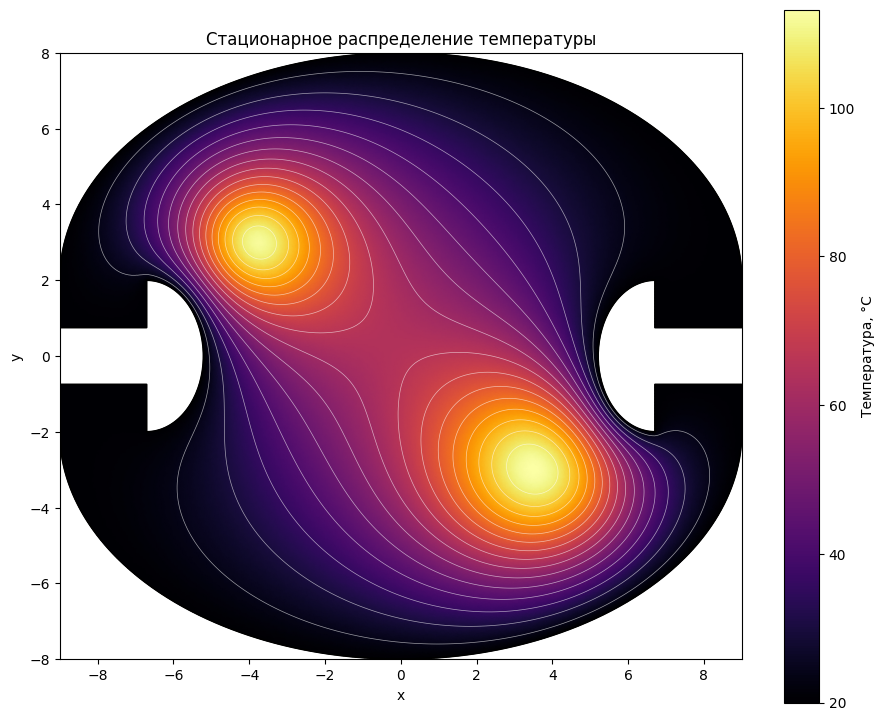

In [622]:
fig, ax = plt.subplots(figsize=(11, 9), dpi=100)

im = ax.tripcolor(mesh, T, shading="gouraud", cmap="inferno")
ax.tricontour(mesh, T, levels=15, colors="white",
              linewidths=0.5, alpha=0.6)

ax.plot(
    np.r_[xs_b, xs_b[0]],
    np.r_[ys_b, ys_b[0]],
    color="black", lw=1.2
)

fig.colorbar(im, ax=ax, label="Температура, °C")

ax.set(
    xlabel="x", ylabel="y",
    title="Стационарное распределение температуры"
)
ax.set_aspect("equal")
plt.show()

In [623]:
f = RHS(mesh.x, mesh.y)
A, rhs_vec, inner_ids = apply_dirichlet(
    L, B @ f, boundary_ids, T0
)

residual = np.linalg.norm(A @ T[inner_ids] - rhs_vec) / np.linalg.norm(rhs_vec)

print(f"Относительная невязка: {residual:.3e}")
print(f"Ошибка граничных условий: {np.max(np.abs(T[boundary_ids] - T0)):.3e}")

Относительная невязка: 7.835e-15
Ошибка граничных условий: 0.000e+00


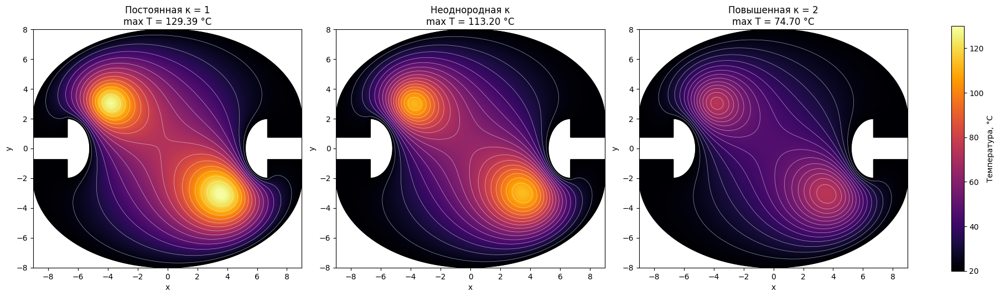

In [624]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

cases = [
    ("Постоянная κ = 1", lambda x, y: 1.0),
    ("Неоднородная κ", kappa),
    ("Повышенная κ = 2", lambda x, y: 2.0),
]

for ax, (title, kv) in zip(axes, cases):
    L_case, B_case = assemble_matrices(mesh, kappa=kv)
    T_case = solve_poisson(mesh, L_case, B_case, RHS, boundary_ids, T0)

    im = ax.tripcolor(
        mesh, T_case, shading="gouraud",
        cmap="inferno", vmin=T0, vmax=130
    )

    ax.tricontour(
        mesh, T_case, levels=15,
        colors="white", linewidths=0.5, alpha=0.6
    )

    ax.plot(
        np.r_[xs_b, xs_b[0]],
        np.r_[ys_b, ys_b[0]],
        color="black", lw=1.2
    )

    ax.set(
        xlabel="x", ylabel="y",
        title=f"{title}\nmax T = {T_case.max():.2f} °C"
    )
    ax.set_aspect("equal")

fig.colorbar(im, ax=axes, label="Температура, °C", shrink=0.75)
plt.show()

# Задача. Распространение волн в комнате Пенроуза

## Постановка

В комнате Пенроуза расположен локальный источник, испускающий волны во всех направлениях. Требуется исследовать их распространение и отражение от стенок.

$$
\begin{cases}
\displaystyle u_{tt}=c^2\Delta u+f(x,y,t), &(x,y)\in\Omega,\quad t>0,\\[4pt]
u|_{\partial\Omega}=0,\\
u(x,y,0)=0,\qquad u_t(x,y,0)=0.
\end{cases}
$$

Локализованный гармонический источник:

$$
f(x,y,t)=Q\exp\left(-\frac{(x-x_s)^2+(y-y_s)^2}{2\sigma_s^2}\right)
\sin(\omega t)
\exp\left(-\frac{(t-t_s)^2}{2\sigma_t^2}\right).
$$


In [625]:
def wave_source(mesh, B, n_inner, x0=0.0, y0=0.0,
                sigma=0.2, omega=8.0, Q=1.0,
                t0=5.0, duration=2.0):
    x, y = mesh.x[:n_inner], mesh.y[:n_inner]

    spatial = Q * np.exp(-((x-x0)**2 + (y-y0)**2) / (2*sigma**2))
    force = B @ spatial

    def source(t):
        temporal = np.sin(omega*t) * np.exp(-(t-t0)**2 / (2*duration**2))
        return temporal * force

    return source

In [626]:
def integrate_wave(L, B, u0, v0, dt=0.05, t_end=30.0,
                   c=1.0, source=None):
    solver = splu(B.tocsc())
    K = c**2 * L

    def acceleration(u, t):
        force = np.zeros_like(u) if source is None else source(t)
        return solver.solve(force - K @ u)

    u_prev = u0.copy()
    u = u0 + dt*v0 + dt**2/2 * acceleration(u0, 0.0)

    yield 0.0, u_prev.copy()
    yield dt, u.copy()

    n_steps = int(np.ceil(t_end / dt))

    for n in range(1, n_steps):
        t = n * dt
        u_next = 2*u - u_prev + dt**2 * acceleration(u, t)

        u_prev, u = u, u_next
        yield (n + 1)*dt, u.copy()

In [627]:
def wave_dt_max(L, B, c=1.0):
    lambda_max = spla.eigsh(
        L, M=B, k=1, which="LA",
        return_eigenvectors=False
    )[0]

    return 2 / (c * np.sqrt(lambda_max))

In [628]:
c_wave = 1.0

L_wave, B_wave = assemble_matrices(mesh)
L_wave = L_wave[:n_inner, :n_inner]
B_wave = B_wave[:n_inner, :n_inner]

dt_max = wave_dt_max(L_wave, B_wave, c=c_wave)
dt = 0.8 * dt_max

print(f"Максимальный шаг: {dt_max:.6f}")
print(f"Выбранный шаг:    {dt:.6f}")

Максимальный шаг: 0.011920
Выбранный шаг:    0.009536


In [629]:
def sample_wave(solution, n_nodes, n_inner, every=2):
    times, frames = [], []

    for k, (t, u_inner) in enumerate(solution):
        if k % every != 0:
            continue

        u_full = np.zeros(n_nodes)
        u_full[:n_inner] = u_inner

        times.append(t)
        frames.append(u_full)

    return np.array(times), frames

In [630]:
def animate_wave(mesh, times, frames, interval=80, filename="wave.mp4",
                 gain=3.0):
    global_vmax = max(np.max(np.abs(u)) for u in frames)
    global_vmax = max(global_vmax, 1e-12)

    def display_field(u):
        z = gain * u / global_vmax
        z = np.clip(z, -1.0, 1.0)
        return z

    fig, ax = plt.subplots(figsize=(8, 7), dpi=100)

    im = ax.tripcolor(
        mesh, display_field(frames[0]),
        shading="gouraud",
        cmap="seismic",
        vmin=-1, vmax=1
    )

    ax.plot(
        np.r_[xs_b, xs_b[0]],
        np.r_[ys_b, ys_b[0]],
        color="black", lw=1.0
    )

    fig.colorbar(im, ax=ax, label="Визуализированная амплитуда")
    ax.set_aspect("equal")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

    def update(i):
        im.set_array(display_field(frames[i]))
        ax.set_title(f"Распространение волнового пакета, t = {times[i]:.2f}")
        return (im,)

    anim = FuncAnimation(
        fig, update,
        frames=len(frames),
        interval=interval,
        blit=False,
        repeat=False
    )

    anim.save(
        filename,
        writer="ffmpeg",
        fps=1000 / interval,
        codec="libx264",
        extra_args=["-pix_fmt", "yuv420p", "-preset", "ultrafast", "-crf", "23"]
    )

    plt.close(fig)
    display(Video(filename, embed=True, mimetype="video/mp4"))

In [631]:
u0 = np.zeros(n_inner)
v0 = np.zeros(n_inner)

source = wave_source(
    mesh, B_wave, n_inner,
    x0=0.0, y0=0.0,
    sigma=0.2, omega=12.0,
    Q=10.0, t0=5.0, duration=2.0
)

solution = integrate_wave(
    L_wave, B_wave, u0, v0,
    dt=dt, t_end=30.0,
    c=c_wave, source=source
)

times, frames = sample_wave(
    solution,
    n_nodes=len(mesh.x),
    n_inner=n_inner,
    every=15
)

animate_wave(mesh, times, frames, interval=40)

In [632]:
source = wave_source(
    mesh, B_wave, n_inner,
    x0=-7.8, y0=1.0,
    sigma=0.2, omega=12.0,
    Q=10.0, t0=5.0, duration=2.0
)

solution = integrate_wave(
    L_wave, B_wave, u0, v0,
    dt=dt, t_end=30.0,
    c=c_wave, source=source
)

times, frames = sample_wave(
    solution,
    n_nodes=len(mesh.x),
    n_inner=n_inner,
    every=15
)

animate_wave(mesh, times, frames, interval=40)